# 벡터·행렬과 선형변환

작은 예제로 원리 확인 → 코드 실행 → 한 조건 변경 → 결과 해석

위에서 아래로 실행. 일반 CPU로 진행 가능. 날짜·평가 운영은 학기 운영안내에서 확인

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display
np.set_printoptions(precision=5, suppress=True)

## 벡터 연산

v=[1,2,3], w=[4,5,6]의 합·내적·크기를 구하시오. 내적의 출력이 벡터인지 스칼라인지 설명하시오.

In [2]:
v = np.array([1.,2.,3.]); w = np.array([4.,5.,6.])
print(v+w, v@w, np.linalg.norm(v))
A = np.arange(1,10).reshape(3,3)
B = np.arange(9,0,-1).reshape(3,3)
print('행렬 곱:'); print(A@B)
print('원소별 곱:'); print(A*B)
assert v@w == 32

[5. 7. 9.] 32.0 3.7416573867739413
행렬 곱:
[[ 30  24  18]
 [ 84  69  54]
 [138 114  90]]
원소별 곱:
[[ 9 16 21]
 [24 25 24]
 [21 16  9]]


## 선형변환

x=[1,1]에 일반 변환·대칭 늘이기·90° 회전·직교투영을 적용하시오. 결과 방향과 길이를 실행 전에 예측하시오.

General [-1.  2.]
Symmetric stretch [3. 3.]
Rotation 90 [-1.  1.]
Orthogonal projection [0.6 1.2]


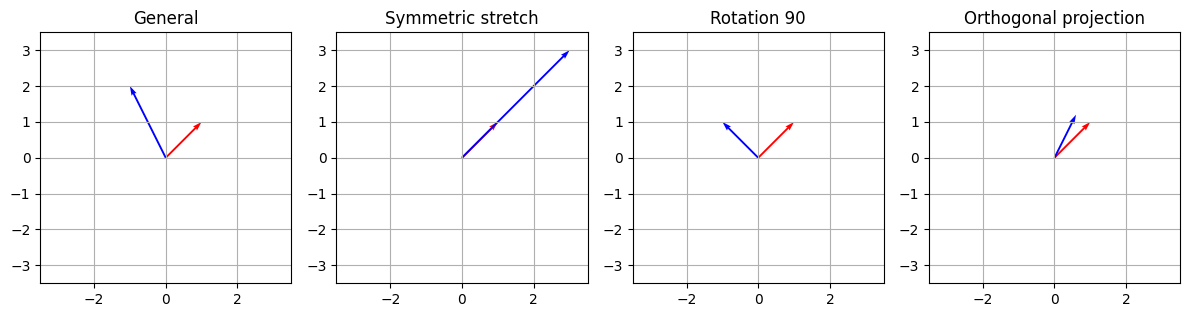

In [3]:
x = np.array([1.,1.]); direction = np.array([1.,2.])
P = np.outer(direction,direction)/(direction@direction)
matrices = {'General':np.array([[2.,-3.],[1.,1.]]),
            'Symmetric stretch':np.array([[2.,1.],[1.,2.]]),
            'Rotation 90':np.array([[0.,-1.],[1.,0.]]),
            'Orthogonal projection':P}
fig, axes = plt.subplots(1,4,figsize=(12,3))
for ax,(name,M) in zip(axes,matrices.items()):
    y = M@x
    for z,color in [(x,'red'),(y,'blue')]:
        ax.quiver(0,0,*z,angles='xy',scale_units='xy',scale=1,color=color)
    ax.set(xlim=(-3.5,3.5),ylim=(-3.5,3.5),title=name); ax.set_aspect('equal');ax.grid()
    print(name, y)
plt.tight_layout();plt.show()
assert np.allclose(P@P,P)
assert np.allclose(P,P.T)
assert np.isclose((x-P@x)@direction,0)

## 변환을 구분하는 조건

행렬 `[[1,0.1],[2,0.2]]`는 모든 출력을 [1,2] 방향에 놓지만 직교투영 행렬은 아니다. 한 번 적용한 결과와 두 번 적용한 결과를 비교하시오. 대칭 늘이기와 전단변환도 구분하시오.

In [4]:
rank_one_map = np.array([[1.,.1],[2.,.2]])
print(rank_one_map@x, rank_one_map@rank_one_map@x)
print('직교투영:', P@x, P@P@x)
print('전단변환 예:', np.array([[1.,1.],[0.,1.]])@x)
assert not np.allclose(rank_one_map@rank_one_map,rank_one_map)

[1.1 2.2] [1.32 2.64]
직교투영: [0.6 1.2] [0.6 1.2]
전단변환 예: [2. 1.]
